In [1]:
import sys
from pathlib import Path

_root = Path.cwd()
while not (_root / "src").exists() and _root != _root.parent:
    _root = _root.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

from src.data import load_data, load_failure_modes, load_raw

INK, MUTED, GRID, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
C_SAIN, C_PANNE = "#2a78d6", "#eb6834"   # bleu / orange 
DIVERGING = "RdBu_r"
NUM = ["air_temp_k", "process_temp_k", "rotational_speed_rpm", "torque_nm", "tool_wear_min"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
})


def box_by_class(ax, s0, s1, title):
    """Boxplot d'une variable : sain (0) vs panne (1)."""
    bp = ax.boxplot([s0, s1], patch_artist=True, widths=0.6, showfliers=False)
    for patch, c in zip(bp["boxes"], [C_SAIN, C_PANNE]):
        patch.set_facecolor(c)
        patch.set_alpha(0.85)
    for med in bp["medians"]:
        med.set_color(INK)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Sain", "Panne"])
    ax.set_title(title, fontsize=8)
    ax.grid(axis="x", visible=False)

## 1. Chargement des données

In [2]:
raw = load_raw()
df = load_data()
modes = load_failure_modes()
print("brut :", raw.shape, "| modelisation :", df.shape, "| modes :", modes.shape)

brut : (10000, 14) | modelisation : (10000, 7) | modes : (10000, 5)


In [3]:
raw.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
df.head()

,type,air_temp_k,process_temp_k,rotational_speed_rpm,torque_nm,tool_wear_min,machine_failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


## 2. Structure et qualité

Types, statistiques descriptives, valeurs manquantes et doublons.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   type                  10000 non-null  str    
 1   air_temp_k            10000 non-null  float64
 2   process_temp_k        10000 non-null  float64
 3   rotational_speed_rpm  10000 non-null  int64  
 4   torque_nm             10000 non-null  float64
 5   tool_wear_min         10000 non-null  int64  
 6   machine_failure       10000 non-null  int64  
dtypes: float64(3), int64(3), str(1)
memory usage: 556.8 KB


In [6]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
air_temp_k,10000.0,300.00,2.00,295.3,298.3,300.1,301.5,304.5
process_temp_k,10000.0,310.01,1.48,305.7,308.8,310.1,311.1,313.8
rotational_speed_rpm,10000.0,1538.78,179.28,1168.0,1423.0,1503.0,1612.0,2886.0
torque_nm,10000.0,39.99,9.97,3.8,33.2,40.1,46.8,76.6
tool_wear_min,10000.0,107.95,63.65,0.0,53.0,108.0,162.0,253.0
machine_failure,10000.0,0.03,0.18,0.0,0.0,0.0,0.0,1.0


In [7]:
print("Valeurs manquantes :", int(df.isna().sum().sum()))
print("Lignes dupliquees  :", int(df.duplicated().sum()))

Valeurs manquantes : 0
Lignes dupliquees  : 0


## 3. Variable cible


{0: 9661, 1: 339} | taux de panne = 0.0339


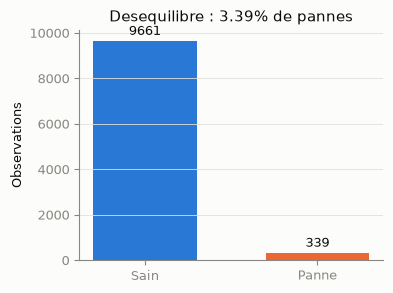

In [8]:
vc = df["machine_failure"].value_counts().sort_index()
print(vc.to_dict(), "| taux de panne =", round(df["machine_failure"].mean(), 4))

fig, ax = plt.subplots(figsize=(4, 3))
bars = ax.bar(["Sain", "Panne"], vc.values, color=[C_SAIN, C_PANNE], width=0.6)
ax.bar_label(bars, padding=2)
ax.set_ylabel("Observations")
ax.set_title(f"Desequilibre : {df['machine_failure'].mean():.2%} de pannes")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## 4. Analyse univariée

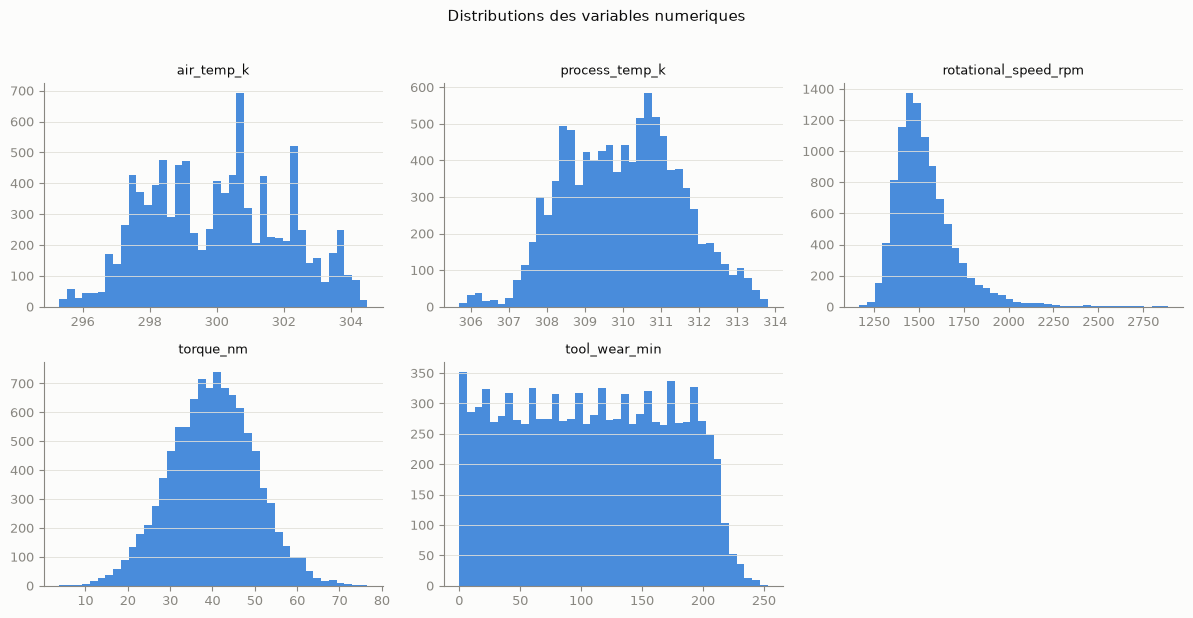

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.ravel(), NUM):
    ax.hist(df[col], bins=40, color=C_SAIN, alpha=0.85)
    ax.set_title(col, fontsize=9)
    ax.grid(axis="x", visible=False)
axes.ravel()[-1].axis("off")  
fig.suptitle("Distributions des variables numeriques", y=1.02)
plt.tight_layout()
plt.show()

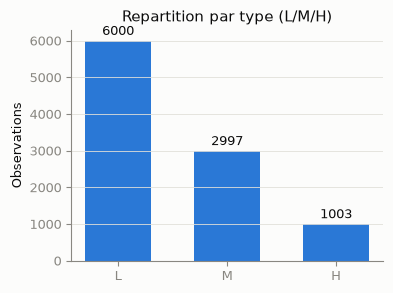

In [10]:
tc = df["type"].value_counts().reindex(["L", "M", "H"])
fig, ax = plt.subplots(figsize=(4, 3))
bars = ax.bar(tc.index, tc.values, color=C_SAIN, width=0.6)
ax.bar_label(bars, padding=2)
ax.set_ylabel("Observations")
ax.set_title("Repartition par type (L/M/H)")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## 5. Cible vs variables

Quelles variables séparent le mieux sain / panne ?

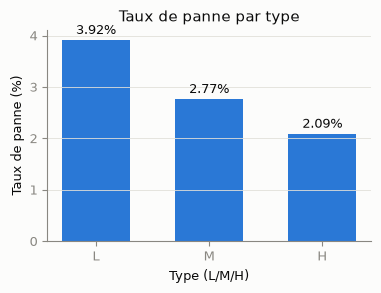

In [11]:
rate = df.groupby("type")["machine_failure"].mean().reindex(["L", "M", "H"]) * 100
fig, ax = plt.subplots(figsize=(4, 3))
bars = ax.bar(rate.index, rate.values, color=C_SAIN, width=0.6)
ax.bar_label(bars, fmt="%.2f%%", padding=2)
ax.set_ylabel("Taux de panne (%)")
ax.set_xlabel("Type (L/M/H)")
ax.set_title("Taux de panne par type")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

In [12]:
df.groupby("machine_failure")[NUM].mean().T.round(2)

machine_failure,0,1
air_temp_k,299.97,300.89
process_temp_k,310.00,310.29
rotational_speed_rpm,1540.26,1496.49
torque_nm,39.63,50.17
tool_wear_min,106.69,143.78


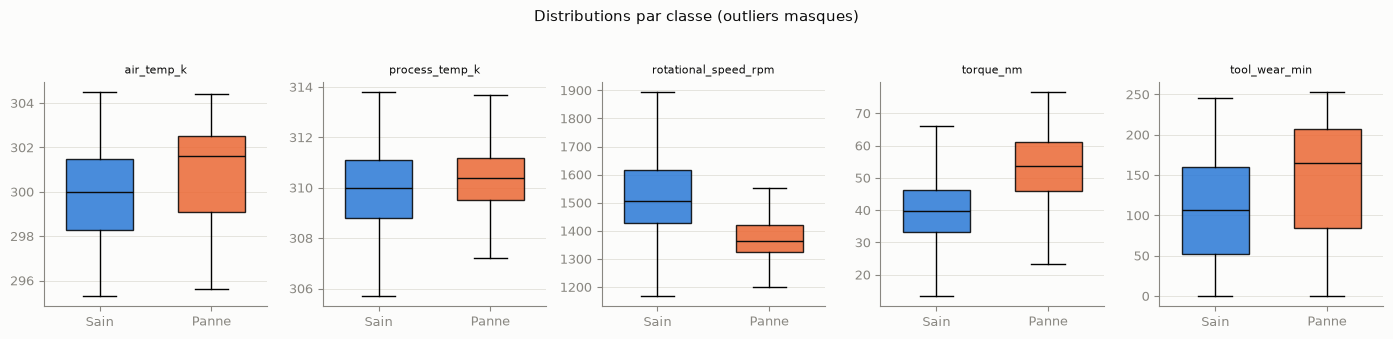

In [13]:
fig, axes = plt.subplots(1, len(NUM), figsize=(14, 3.2))
for ax, col in zip(axes, NUM):
    g0 = df[df["machine_failure"] == 0][col]
    g1 = df[df["machine_failure"] == 1][col]
    box_by_class(ax, g0, g1, col)
fig.suptitle("Distributions par classe (outliers masques)", y=1.04)
plt.tight_layout()
plt.show()

**Test de Mann-Whitney** (non paramétrique) : la variable diffère-t-elle
significativement entre sain et panne ? Plus `p_value` est faible, plus l'écart est net.

In [14]:
rows = []
for col in NUM:
    g0 = df[df["machine_failure"] == 0][col]
    g1 = df[df["machine_failure"] == 1][col]
    u, p = mannwhitneyu(g0, g1, alternative="two-sided")
    rows.append({"feature": col, "U": u, "p_value": p})
pd.DataFrame(rows).sort_values("p_value").reset_index(drop=True)

,feature,U,p_value
0,torque_nm,752493.0,2.262232e-64
1,rotational_speed_rpm,2510959.0,9.706908e-63
2,tool_wear_min,1106611.0,2.916461e-24
3,air_temp_k,1202819.0,8.656108e-17
4,process_temp_k,1428896.5,6.486083e-05


## 6. Modes de panne

Les 5 modes (`TWF, HDF, PWF, OSF, RNF`) sont les *composantes* du label 

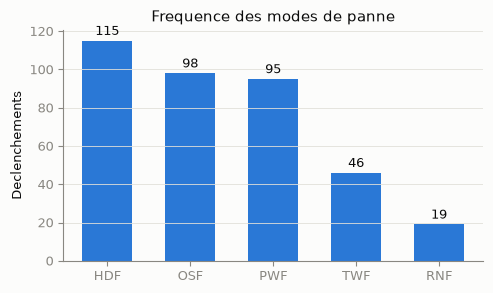

In [15]:
mc = modes.sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar(mc.index, mc.values, color=C_SAIN, width=0.6)
ax.bar_label(bars, padding=2)
ax.set_ylabel("Declenchements")
ax.set_title("Frequence des modes de panne")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

In [16]:
or_modes = modes.max(axis=1)
fail = df["machine_failure"]
print("panne sans aucun mode :", int(((fail == 1) & (or_modes == 0)).sum()))
print("mode actif sans panne :", int(((fail == 0) & (or_modes == 1)).sum()))
print("lignes multi-modes    :", int((modes.sum(axis=1) > 1).sum()))

panne sans aucun mode : 9
mode actif sans panne : 18
lignes multi-modes    : 24


**Co-occurrence des modes** (diagonale = total par mode ; hors-diagonale = simultanéités) :

In [17]:
modes.T.dot(modes)

,TWF,HDF,PWF,OSF,RNF
TWF,46,0,1,3,1
HDF,0,115,3,6,0
PWF,1,3,95,12,0
OSF,3,6,12,98,0
RNF,1,0,0,0,19


**Signature de chaque mode** : moyenne des variables quand le mode est actif.


In [18]:
rows = []
for m in modes.columns:
    mask = modes[m] == 1
    s = df.loc[mask, NUM].mean()
    s["n"] = int(mask.sum())
    s.name = m
    rows.append(s)
pd.DataFrame(rows).round(1)

,air_temp_k,process_temp_k,rotational_speed_rpm,torque_nm,tool_wear_min,n
TWF,300.3,310.2,1566.2,37.8,216.4,46.0
HDF,302.6,310.8,1337.3,53.2,107.2,115.0
PWF,300.1,310.0,1764.0,48.5,101.9,95.0
OSF,300.0,310.1,1350.3,58.4,207.7,98.0
RNF,300.8,310.8,1485.0,43.7,124.5,19.0


## 7. Feature engineering

Trois variables physiques, dérivées du procédé et alignées sur les modes de panne :
- **puissance** = couple × vitesse angulaire : *power failure* (PWF)
- ** $\delta$ T** = temp. procédé − temp. air : *heat dissipation* (HDF)
- **usure $\times$ couple** : *overstrain* (OSF)

In [19]:
eng = df.copy()
eng["power_w"] = eng["torque_nm"] * eng["rotational_speed_rpm"] * 2 * np.pi / 60
eng["delta_t_k"] = eng["process_temp_k"] - eng["air_temp_k"]
eng["wear_x_torque"] = eng["tool_wear_min"] * eng["torque_nm"]
ENG = ["power_w", "delta_t_k", "wear_x_torque"]
eng[ENG].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
power_w,10000.0,6279.74,1067.42,1148.44,5561.18,6271.03,7003.0,10469.92
delta_t_k,10000.0,10.00,1.00,7.60,9.30,9.80,11.0,12.10
wear_x_torque,10000.0,4314.66,2826.57,0.00,1963.65,4012.95,6279.0,16497.00


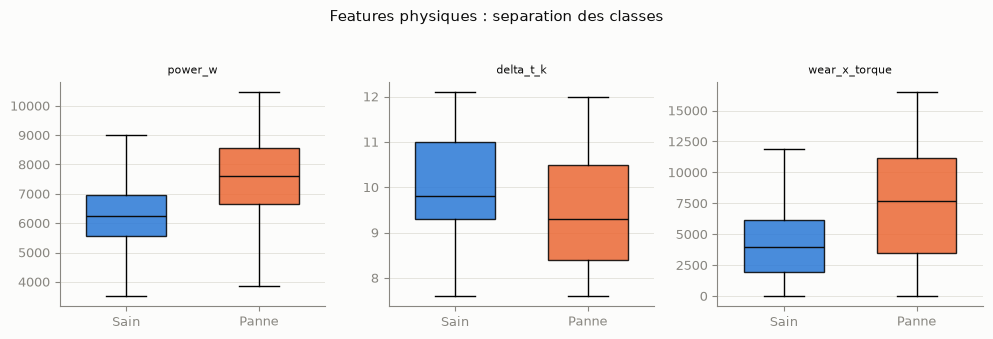

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, col in zip(axes, ENG):
    g0 = eng[eng["machine_failure"] == 0][col]
    g1 = eng[eng["machine_failure"] == 1][col]
    box_by_class(ax, g0, g1, col)
fig.suptitle("Features physiques : separation des classes", y=1.04)
plt.tight_layout()
plt.show()

**Corrélation de chaque variable avec la panne** - tri croissant :

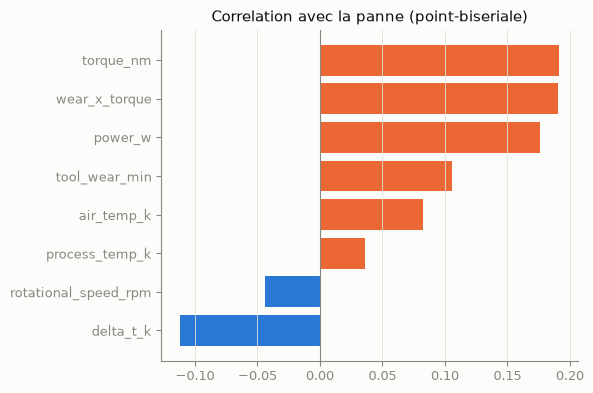

delta_t_k              -0.112
rotational_speed_rpm   -0.044
process_temp_k          0.036
air_temp_k              0.083
tool_wear_min           0.105
power_w                 0.176
wear_x_torque           0.190
torque_nm               0.191
Name: machine_failure, dtype: float64

In [21]:
allf = NUM + ENG
corr_t = eng[allf + ["machine_failure"]].corr()["machine_failure"].drop("machine_failure").sort_values()
fig, ax = plt.subplots(figsize=(6, 4))
colors = [C_PANNE if v > 0 else C_SAIN for v in corr_t.values]
ax.barh(corr_t.index, corr_t.values, color=colors)
ax.axvline(0, color=MUTED, linewidth=0.8)
ax.set_title("Correlation avec la panne (point-biseriale)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
corr_t.round(3)

## 8. Corrélations et multicolinéarité

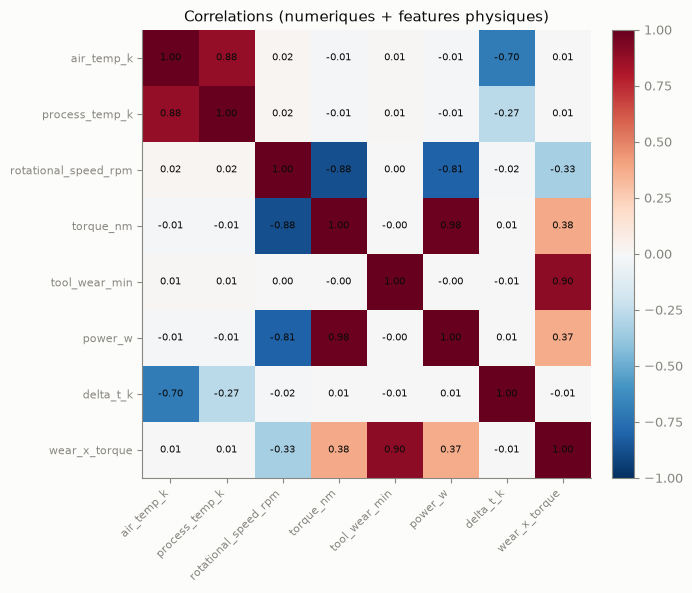

In [22]:
cols = NUM + ENG
corr = eng[cols].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(cols)))
ax.set_yticklabels(cols, fontsize=8)
ax.grid(visible=False)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7, color=INK)
fig.colorbar(im, fraction=0.046, pad=0.04)
ax.set_title("Correlations (numeriques + features physiques)")
plt.tight_layout()
plt.show()

## 9. Séparabilité (vue 2D)

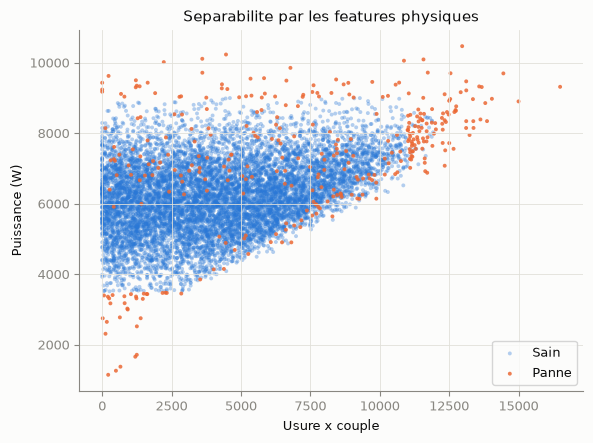

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for cls, color, label, alpha in [(0, C_SAIN, "Sain", 0.35), (1, C_PANNE, "Panne", 0.85)]:
    sub = eng[eng["machine_failure"] == cls]
    ax.scatter(sub["wear_x_torque"], sub["power_w"], s=8, alpha=alpha,
               color=color, label=label, edgecolors="none")
ax.set_xlabel("Usure x couple")
ax.set_ylabel("Puissance (W)")
ax.set_title("Separabilite par les features physiques")
ax.legend()
ax.grid(visible=True)
plt.tight_layout()
plt.show()